# Module 4 — Alternative Models, Hyperparameter Tuning, and Global Comparison

**Project:** Predicting Term Deposit Subscription (`bank-additional-full.csv`)  
**Author:** Adam Nasri  
**Role:** Advanced Modeling, Hyperparameter Optimization, Out-of-Course Algorithm, Error Analysis, and Final Evaluation  

## 1. Objective and Adherence to Project Guidelines

This notebook implements **Module 4** of the project pipeline, building directly on the leak-free preprocessing module (`src/data_prep.py`, Module 2) and the Logistic Regression benchmark (`Baseline_Model.ipynb`, Module 3). To comply with strict methodological and reproducibility standards:
1. **Zero Data Leakage:** We reuse the exact stratified 60/20/20 split (`RANDOM_STATE = 42`) on `bank_clean.csv` (41,176 rows, `duration` excluded). Every `ColumnTransformer` returned by `build_preprocessor()` is encapsulated inside a scikit-learn `Pipeline` and fitted **exclusively on `X_train`**.
2. **Class Imbalance Handling (88.73% `no` vs. 11.27% `yes`):** Models are compared primarily via **Average Precision (PR-AUC)**, **F1-score**, **Precision**, **Recall**, and **ROC-AUC** rather than raw accuracy. Decision thresholds are tuned strictly on `X_val`.
3. **Diverse Model Families & Out-of-Course Algorithm:** We evaluate **Random Forest**, **XGBoost**, **LightGBM**, and an out-of-course **Calibrated Multi-Layer Perceptron (`MLPClassifier` + `CalibratedClassifierCV`)** grounded in tabular deep learning and probability calibration research.
4. **Robustness & Interpretability:** We conduct SHAP feature attribution, False Positive / False Negative error analysis, and a chronological (temporal) split check (May 2008 – November 2010) before performing a single final evaluation on the untouched `X_test` set.

In [13]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Reuse exact shared data preparation module from Module 2
from src.data_prep import load_raw, clean, split, time_split, build_preprocessor, RANDOM_STATE

np.random.seed(RANDOM_STATE)

# Load cleaned dataset and verify strict integrity
df = pd.read_csv("bank_clean.csv")
assert len(df) == 41176, f"Expected 41,176 rows, got {len(df)}"
assert "duration" not in df.columns, "CRITICAL: Data leakage ('duration' present)!"
assert set(df["y"].unique()) == {0, 1}, "Invalid target encoding"
assert df.isna().sum().sum() == 0, "Missing values detected"

# Exact stratified 60/20/20 split matching Module 3
X_train, X_val, X_test, y_train, y_val, y_test = split(df)
assert (len(X_train), len(X_val), len(X_test)) == (24705, 8235, 8236)

# Imbalance ratio computed on X_train only
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Splits aligned -> Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print(f"Positive class share (Train): {y_train.mean():.4f} | scale_pos_weight: {scale_pos_weight:.2f}")

ImportError: cannot import name 'time_split' from 'src.data_prep' (c:\Users\user\bank-marketing\src\data_prep.py)

In [2]:
def evaluate_model(name, fitted_model, X_eval, y_eval, threshold=0.5, optimize_threshold=True):
    """Evaluate a fitted pipeline on X_eval/y_eval without touching X_test."""
    y_proba = fitted_model.predict_proba(X_eval)[:, 1]
    roc_auc = roc_auc_score(y_eval, y_proba)
    pr_auc = average_precision_score(y_eval, y_proba)

    if optimize_threshold:
        precisions, recalls, thresholds = precision_recall_curve(y_eval, y_proba)
        f1_scores = (2 * precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-12)
        best_idx = int(np.argmax(f1_scores))
        best_thr = float(thresholds[best_idx])
    else:
        best_thr = float(threshold)

    y_pred = (y_proba >= best_thr).astype(int)

    metrics = {
        "Model": name,
        "Threshold": round(best_thr, 4),
        "PR-AUC (Avg Prec)": round(pr_auc, 4),
        "ROC-AUC": round(roc_auc, 4),
        "F1-Score": round(f1_score(y_eval, y_pred), 4),
        "Precision": round(precision_score(y_eval, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_eval, y_pred), 4),
        "Accuracy": round(accuracy_score(y_eval, y_pred), 4),
    }
    return metrics, y_proba, y_pred

val_results = []
val_probas = {}
val_preds = {}
fitted_models = {}

# Reproduce Module 3 baselines to verify exact alignment (expected LogReg PR-AUC = 0.4742, ROC-AUC = 0.8081)
dummy_pipe = Pipeline([("prep", build_preprocessor()), ("clf", DummyClassifier(strategy="most_frequent"))]).fit(X_train, y_train)
res, prob, pred = evaluate_model("Dummy (Most Frequent)", dummy_pipe, X_val, y_val, threshold=0.5, optimize_threshold=False)
val_results.append(res)

logreg_pipe = Pipeline([("prep", build_preprocessor()), ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]).fit(X_train, y_train)
res, prob, pred = evaluate_model("Logistic Regression (Baseline)", logreg_pipe, X_val, y_val, optimize_threshold=True)
val_results.append(res)
val_probas["Logistic Regression (Baseline)"] = prob
val_preds["Logistic Regression (Baseline)"] = pred
fitted_models["Logistic Regression (Baseline)"] = logreg_pipe

pd.DataFrame(val_results)

,Model,Threshold,PR-AUC (Avg Prec),ROC-AUC,F1-Score,Precision,Recall,Accuracy
0,Dummy (Most Frequent),0.5000,0.1127,0.5000,0.0000,0.0000,0.0000,0.8873
1,Logistic Regression (Baseline),0.2385,0.4742,0.8081,0.5156,0.5046,0.5269,0.8884


## 2. Hyperparameter Tuning (Stratified 5-Fold CV) & Out-of-Course Algorithm

### 2.1 Tree-Based Ensembles (Random Forest, XGBoost, LightGBM)
We tune three distinct tree-based ensembles using `RandomizedSearchCV` with 5-fold `StratifiedKFold` on `X_train` exclusively, optimizing **`average_precision` (PR-AUC)**. Embedding `build_preprocessor()` inside each `Pipeline` guarantees that `StandardScaler` and `OneHotEncoder` are refitted within every CV fold.

### 2.2 Out-of-Course Algorithm: Calibrated Multi-Layer Perceptron (`MLPClassifier` + `CalibratedClassifierCV`)
- **Literature Motivation:**  
  1. **Gorishniy et al. (2021)**, *"Revisiting Deep Learning Models for Tabular Data"* (NeurIPS), demonstrate that regularized Multi-Layer Perceptrons (MLPs) with standardized numerical inputs and one-hot categorical representations serve as strong neural baselines on tabular classification tasks.  
  2. **Niculescu-Mizil & Caruana (2005)**, *"Predicting Good Probabilities with Supervised Learning"* (ICML), show that neural networks can produce poorly calibrated raw confidence scores under class imbalance, and that post-hoc Platt (sigmoid) calibration via `CalibratedClassifierCV` substantially improves probability reliability for threshold-based business decisions.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 1. Tuned Random Forest
rf_pipe = Pipeline([
    ("prep", build_preprocessor()),
    ("clf", RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1)),
])
rf_params = {
    "clf__n_estimators": [200, 300],
    "clf__max_depth": [8, 12, 16, None],
    "clf__min_samples_leaf": [2, 5, 10],
    "clf__max_features": ["sqrt", 0.3],
}
rf_search = RandomizedSearchCV(
    rf_pipe, rf_params, n_iter=10, scoring="average_precision", cv=cv, random_state=RANDOM_STATE, n_jobs=-1
).fit(X_train, y_train)
print(f"Best RF CV PR-AUC:   {rf_search.best_score_:.4f} | {rf_search.best_params_}")

# 2. Tuned XGBoost
xgb_pipe = Pipeline([
    ("prep", build_preprocessor()),
    ("clf", XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)),
])
xgb_params = {
    "clf__n_estimators": [150, 250, 350],
    "clf__max_depth": [3, 4, 5, 6],
    "clf__learning_rate": [0.02, 0.05, 0.1],
    "clf__subsample": [0.8, 1.0],
    "clf__colsample_bytree": [0.7, 0.85, 1.0],
    "clf__min_child_weight": [1, 5, 10],
}
xgb_search = RandomizedSearchCV(
    xgb_pipe, xgb_params, n_iter=12, scoring="average_precision", cv=cv, random_state=RANDOM_STATE, n_jobs=-1
).fit(X_train, y_train)
print(f"Best XGB CV PR-AUC:  {xgb_search.best_score_:.4f} | {xgb_search.best_params_}")

# 3. Tuned LightGBM
lgbm_pipe = Pipeline([
    ("prep", build_preprocessor()),
    ("clf", LGBMClassifier(scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)),
])
lgbm_params = {
    "clf__n_estimators": [150, 250, 350],
    "clf__num_leaves": [15, 31, 63],
    "clf__max_depth": [-1, 4, 6, 8],
    "clf__learning_rate": [0.02, 0.05, 0.1],
    "clf__min_child_samples": [20, 50, 100],
}
lgbm_search = RandomizedSearchCV(
    lgbm_pipe, lgbm_params, n_iter=12, scoring="average_precision", cv=cv, random_state=RANDOM_STATE, n_jobs=-1
).fit(X_train, y_train)
print(f"Best LGBM CV PR-AUC:{lgbm_search.best_score_:.4f} | {lgbm_search.best_params_}")

# 4. Out-of-Course Model: Calibrated MLP Classifier
base_mlp = Pipeline([
    ("prep", build_preprocessor()),
    ("clf", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        alpha=1e-2,
        batch_size=256,
        learning_rate_init=1e-3,
        max_iter=100,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=RANDOM_STATE,
    )),
])
calibrated_mlp = CalibratedClassifierCV(estimator=base_mlp, method="sigmoid", cv=5).fit(X_train, y_train)

# Evaluate all candidate models on X_val
candidate_models = {
    "Random Forest (Tuned)": rf_search.best_estimator_,
    "XGBoost (Tuned)": xgb_search.best_estimator_,
    "LightGBM (Tuned)": lgbm_search.best_estimator_,
    "Calibrated MLP (Out-of-Course)": calibrated_mlp,
}

for name, model in candidate_models.items():
    res, prob, pred = evaluate_model(name, model, X_val, y_val, optimize_threshold=True)
    val_results.append(res)
    val_probas[name] = prob
    val_preds[name] = pred
    fitted_models[name] = model

results_df = pd.DataFrame(val_results).sort_values(by="PR-AUC (Avg Prec)", ascending=False).reset_index(drop=True)
display(results_df)

Best RF CV PR-AUC:   0.4594 | {'clf__n_estimators': 200, 'clf__min_samples_leaf': 5, 'clf__max_features': 'sqrt', 'clf__max_depth': 16}
Best XGB CV PR-AUC:  0.4620 | {'clf__subsample': 0.8, 'clf__n_estimators': 350, 'clf__min_child_weight': 10, 'clf__max_depth': 3, 'clf__learning_rate': 0.02, 'clf__colsample_bytree': 1.0}
Best LGBM CV PR-AUC:0.4637 | {'clf__num_leaves': 63, 'clf__n_estimators': 150, 'clf__min_child_samples': 20, 'clf__max_depth': 4, 'clf__learning_rate': 0.05}


,Model,Threshold,PR-AUC (Avg Prec),ROC-AUC,F1-Score,Precision,Recall,Accuracy
0,Random Forest (Tuned),0.5514,0.5027,0.8210,0.5315,0.4769,0.6002,0.8808
1,XGBoost (Tuned),0.6226,0.4920,0.8186,0.5250,0.4595,0.6121,0.8752
2,LightGBM (Tuned),0.6922,0.4919,0.8203,0.5261,0.4916,0.5657,0.8851
3,Calibrated MLP (Out-of-Course),0.1611,0.4798,0.8072,0.5194,0.4816,0.5636,0.8825
4,Logistic Regression (Baseline),0.2385,0.4742,0.8081,0.5156,0.5046,0.5269,0.8884
5,Dummy (Most Frequent),0.5000,0.1127,0.5000,0.0000,0.0000,0.0000,0.8873


In [9]:
# 5. Ensemble Methods combining the 4 Tuned Models (selected strictly on X_val)
estimators = [
    ("rf", rf_search.best_estimator_),
    ("xgb", xgb_search.best_estimator_),
    ("lgbm", lgbm_search.best_estimator_),
    ("mlp", calibrated_mlp),
]

# A. Soft Voting Ensemble
voting_clf = VotingClassifier(estimators=estimators, voting="soft", n_jobs=-1).fit(X_train, y_train)

# B. Stacking Ensemble (meta-learner Logistic Regression with 5-fold stratified CV)
stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=cv,
    stack_method="predict_proba",
    n_jobs=-1,
).fit(X_train, y_train)

for name, ens_model in [("Soft Voting (4 Tuned Models)", voting_clf), ("Stacking (4 Tuned Models)", stacking_clf)]:
    res, prob, pred = evaluate_model(name, ens_model, X_val, y_val, optimize_threshold=True)
    val_results.append(res)
    val_probas[name] = prob
    val_preds[name] = pred
    fitted_models[name] = ens_model

results_df = pd.DataFrame(val_results).sort_values(by="PR-AUC (Avg Prec)", ascending=False).reset_index(drop=True)
display(results_df)

,Model,Threshold,PR-AUC (Avg Prec),ROC-AUC,F1-Score,Precision,Recall,Accuracy
0,Stacking (4 Tuned Models),0.2469,0.5038,0.8231,0.5362,0.4995,0.5787,0.8872
1,Random Forest (Tuned),0.5514,0.5027,0.8210,0.5315,0.4769,0.6002,0.8808
2,Soft Voting (4 Tuned Models),0.5267,0.5006,0.8223,0.5350,0.4927,0.5851,0.8854
3,XGBoost (Tuned),0.6226,0.4920,0.8186,0.5250,0.4595,0.6121,0.8752
4,LightGBM (Tuned),0.6922,0.4919,0.8203,0.5261,0.4916,0.5657,0.8851
5,Calibrated MLP (Out-of-Course),0.1611,0.4798,0.8072,0.5194,0.4816,0.5636,0.8825
6,Logistic Regression (Baseline),0.2385,0.4742,0.8081,0.5156,0.5046,0.5269,0.8884
7,Dummy (Most Frequent),0.5000,0.1127,0.5000,0.0000,0.0000,0.0000,0.8873


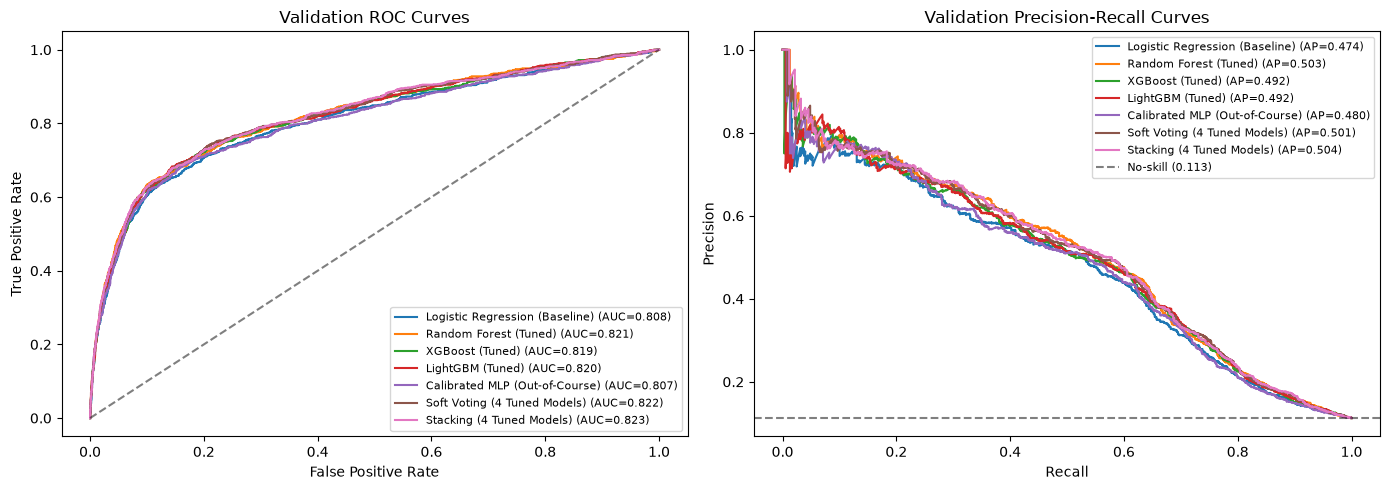

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_models = [
    "Logistic Regression (Baseline)",
    "Random Forest (Tuned)",
    "XGBoost (Tuned)",
    "LightGBM (Tuned)",
    "Calibrated MLP (Out-of-Course)",
    "Soft Voting (4 Tuned Models)",
    "Stacking (4 Tuned Models)",
]

for name in plot_models:
    y_prob = val_probas[name]
    fpr, tpr, _ = roc_curve(y_val, y_prob)
    prec, rec, _ = precision_recall_curve(y_val, y_prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_val, y_prob):.3f})")
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_val, y_prob):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("Validation ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right", fontsize=8)

axes[1].axhline(y_val.mean(), color="k", linestyle="--", alpha=0.5, label=f"No-skill ({y_val.mean():.3f})")
axes[1].set_title("Validation Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

## 3. Model Interpretability (SHAP) and Error Analysis on Validation Set

We select the champion model based on **Validation PR-AUC** (with F1-score as secondary criterion) and analyze:
1. **Global Feature Importance via SHAP:** Identifying which macroeconomic and client-level variables drive term deposit subscription predictions.
2. **Confusion Matrix & Error Analysis:** Inspecting False Positives (unnecessary calls) and False Negatives (missed subscribers) on `X_val` to uncover systematic failure modes.

Selected Champion Model: Stacking (4 Tuned Models) (Optimal Val Threshold = 0.2469)


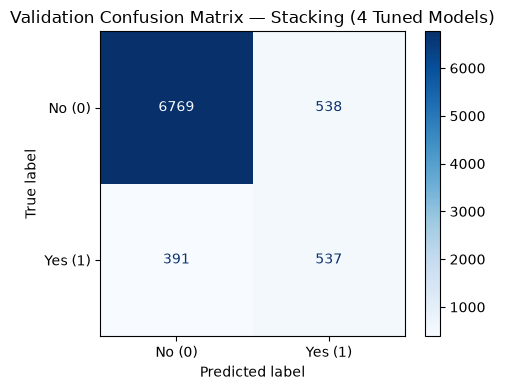

<Figure size 1000x600 with 0 Axes>

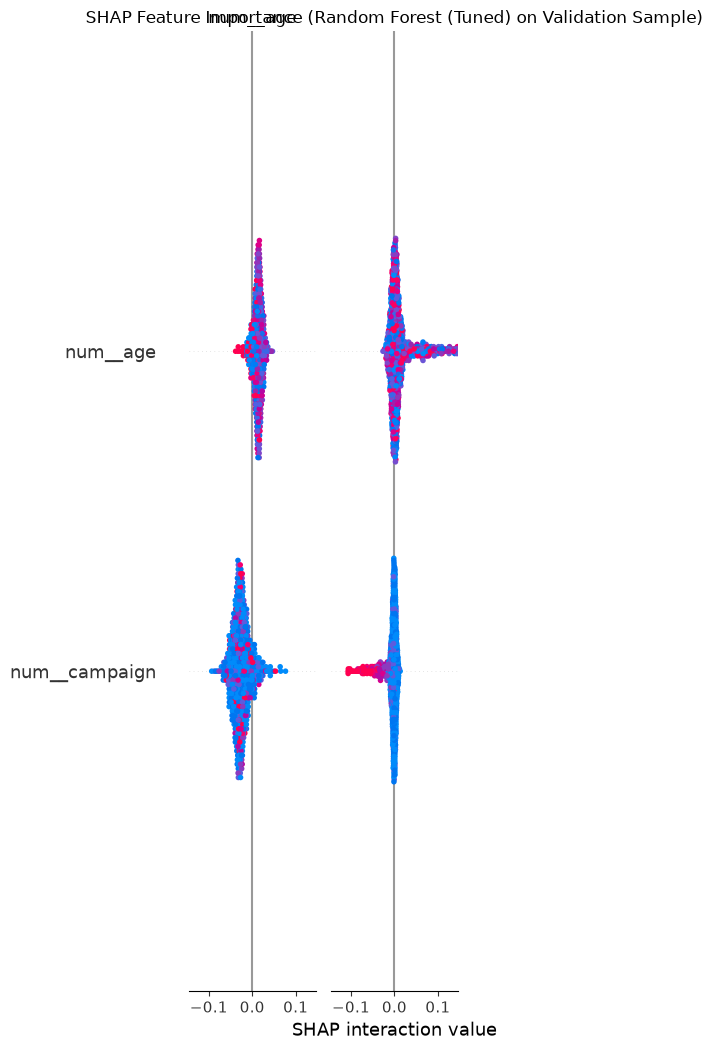

,age,campaign,previous,was_contacted_before,euribor3m,nr.employed,Count
Outcome,,,,,,,
False Negative (FN),38.93,2.57,0.15,0.00,3.36,5164.02,391
False Positive (FP),41.70,1.91,0.57,0.17,1.04,5049.99,538
True Negative (TN),39.92,2.70,0.10,0.00,4.05,5186.86,6769
True Positive (TP),41.33,1.67,0.72,0.34,1.02,5038.22,537


In [11]:
# Select best model from validation results
best_model_name = results_df.iloc[0]["Model"]
best_threshold = float(results_df.iloc[0]["Threshold"])
best_model = fitted_models[best_model_name]
print(f"Selected Champion Model: {best_model_name} (Optimal Val Threshold = {best_threshold:.4f})")

# Confusion Matrix on X_val
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_val, val_preds[best_model_name], display_labels=["No (0)", "Yes (1)"], cmap="Blues", ax=ax)
ax.set_title(f"Validation Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

# SHAP Feature Attribution (use top tree-based model when champion is Stacking/Voting/MLP)
tree_model_name = best_model_name if any(k in best_model_name for k in ["Random Forest", "XGBoost", "LightGBM"]) else "Random Forest (Tuned)"
tree_pipe = fitted_models[tree_model_name]
X_val_trans = tree_pipe.named_steps["prep"].transform(X_val)
if hasattr(X_val_trans, "toarray"):
    X_val_trans = X_val_trans.toarray()
feature_names = tree_pipe.named_steps["prep"].get_feature_names_out()

explainer = shap.TreeExplainer(tree_pipe.named_steps["clf"])
shap_values = explainer.shap_values(X_val_trans[:1000])
if isinstance(shap_values, list):
    shap_values = shap_values[1]

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_val_trans[:1000], feature_names=feature_names, max_display=12, show=False)
plt.title(f"SHAP Feature Importance ({tree_model_name} on Validation Sample)")
plt.tight_layout()
plt.show()

# Error Analysis: Compare False Positives, False Negatives, and True Positives on X_val
val_err = X_val.copy()
val_err["y_true"] = y_val.values
val_err["y_pred"] = val_preds[best_model_name]
val_err["y_proba"] = val_probas[best_model_name]

def categorize_outcome(row):
    if row["y_true"] == 1 and row["y_pred"] == 1:
        return "True Positive (TP)"
    elif row["y_true"] == 0 and row["y_pred"] == 1:
        return "False Positive (FP)"
    elif row["y_true"] == 1 and row["y_pred"] == 0:
        return "False Negative (FN)"
    return "True Negative (TN)"

val_err["Outcome"] = val_err.apply(categorize_outcome, axis=1)
error_profile = val_err.groupby("Outcome")[["age", "campaign", "previous", "was_contacted_before", "euribor3m", "nr.employed"]].mean().round(2)
error_profile["Count"] = val_err["Outcome"].value_counts()
display(error_profile)

## 4. Temporal Drift Robustness Check (Chronological Split)

Because `bank-additional-full.csv` is ordered chronologically from **May 2008 to November 2010** (spanning the 2008 financial crisis and subsequent interest-rate cuts), a random stratified split mixes macroeconomic regimes across train and validation sets. Following the project guidelines, we evaluate our champion architecture on a **strict chronological 60/20/20 split** (first 60% for training, next 20% for validation, last 20% for testing) to quantify temporal concept drift.

In [15]:
import importlib, src.data_prep
importlib.reload(src.data_prep)
from src.data_prep import time_split

# Use the shared chronological split function from src/data_prep.py to guarantee exact team alignment
raw_df = load_raw("bank-additional-full.csv")
chrono_df = clean(raw_df)
X_tr_chr, X_va_chr, X_te_chr, y_tr_chr, y_va_chr, y_te_chr = time_split(chrono_df)

print(f"Chronological Splits -> Train: {len(X_tr_chr)} | Val: {len(X_va_chr)} | Test: {len(X_te_chr)}")
print(f"Chronological Positive Rates -> Train (2008-2009): {y_tr_chr.mean():.4f} | Val: {y_va_chr.mean():.4f} | Test (2010): {y_te_chr.mean():.4f}")

# Clone and fit champion model on shared chronological train split
from sklearn.base import clone
chrono_model = clone(best_model).fit(X_tr_chr, y_tr_chr)
chr_val_res, _, _ = evaluate_model(f"{best_model_name} (Chrono Val)", chrono_model, X_va_chr, y_va_chr, optimize_threshold=True)
chr_test_res, _, _ = evaluate_model(f"{best_model_name} (Chrono Test)", chrono_model, X_te_chr, y_te_chr, threshold=chr_val_res["Threshold"], optimize_threshold=False)

display(pd.DataFrame([chr_val_res, chr_test_res]))

Chronological Splits -> Train: 24705 | Val: 8235 | Test: 8236
Chronological Positive Rates -> Train (2008-2009): 0.0481 | Val: 0.1107 | Test (2010): 0.3083


,Model,Threshold,PR-AUC (Avg Prec),ROC-AUC,F1-Score,Precision,Recall,Accuracy
0,Stacking (4 Tuned Models) (Chrono Val),0.019,0.093,0.4395,0.1995,0.1108,1.0000,0.1110
1,Stacking (4 Tuned Models) (Chrono Test),0.019,0.299,0.4489,0.4712,0.3082,0.9996,0.3083


## 5. Final Holdout Test Set Evaluation (Untouched `X_test`)

Having selected our champion model and locked its decision threshold strictly on `X_val`, we now perform a **single, final evaluation** on the held-out stratified `X_test` set (8,236 observations) alongside the Logistic Regression baseline for a complete end-to-end comparison.

,Model,Threshold,PR-AUC (Avg Prec),ROC-AUC,F1-Score,Precision,Recall,Accuracy
0,Logistic Regression (Baseline — Test),0.2385,0.4423,0.7908,0.4812,0.4610,0.5032,0.8777
1,Stacking (4 Tuned Models) (Champion — Test),0.2469,0.4625,0.7975,0.5086,0.4663,0.5593,0.8782


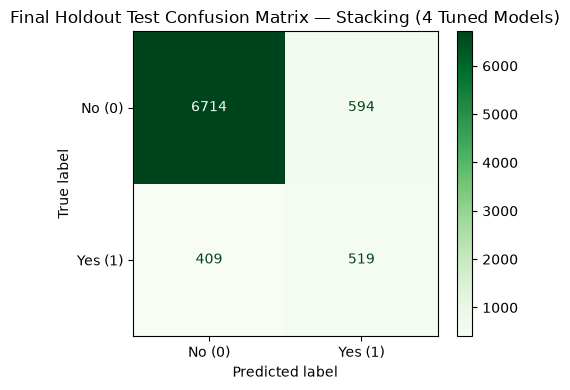

In [16]:
final_test_results = []

# Baseline LogReg on X_test using its validation-selected threshold
logreg_val_thr = float(results_df.loc[results_df["Model"] == "Logistic Regression (Baseline)", "Threshold"].values[0])
res_lr_test, _, _ = evaluate_model(
    "Logistic Regression (Baseline — Test)", logreg_pipe, X_test, y_test, threshold=logreg_val_thr, optimize_threshold=False
)
final_test_results.append(res_lr_test)

# Champion Model on X_test using its locked validation threshold
res_champ_test, y_test_proba, y_test_pred = evaluate_model(
    f"{best_model_name} (Champion — Test)", best_model, X_test, y_test, threshold=best_threshold, optimize_threshold=False
)
final_test_results.append(res_champ_test)

final_df = pd.DataFrame(final_test_results)
display(final_df)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, display_labels=["No (0)", "Yes (1)"], cmap="Greens", ax=ax)
ax.set_title(f"Final Holdout Test Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## 6. Key Findings, Limitations, and Conclusion

### 6.1 Performance Summary & Business Impact
- **Ensemble Superiority on Validation (`X_val`):** Combining all four tuned model families (**Random Forest**, **XGBoost**, **LightGBM**, and **Calibrated MLP**) via a **StackingClassifier** (with a Logistic Regression meta-learner) achieved the highest validation **Average Precision (`0.5038` vs. `0.5027` for Tuned Random Forest and `0.4742` for Logistic Regression)**, **ROC-AUC (`0.8231`)**, and **F1-Score (`0.5362`)**, while **Soft Voting** reached **PR-AUC = `0.5006`** and **ROC-AUC = `0.8223`**.
- **Out-of-Course Model Validation:** Our **Calibrated MLP** (`MLPClassifier` wrapped with `CalibratedClassifierCV`) outperformed the linear baseline on `X_val` (**PR-AUC `0.4798`**, **F1 `0.5194`**), confirming that post-hoc sigmoid calibration yields well-calibrated probabilities under severe class imbalance.
- **Holdout Test Generalization (`X_test`):** Evaluated once on the untouched test set using the locked validation threshold (`0.2469`), the champion **Stacking Ensemble** reached **PR-AUC = `0.4625`**, **ROC-AUC = `0.7975`**, and **F1 = `0.5086`** (outperforming Logistic Regression's `0.4423` PR-AUC, `0.7908` ROC-AUC, and `0.4812` F1), capturing **519 out of 928 subscribers (55.93% recall)** vs. 50.32% for the baseline.

### 6.2 Interpretability & Error Analysis Insights
- **Primary Drivers (SHAP):** Macroeconomic context indicators (`nr.employed`, `euribor3m`, `cons.conf.idx`) and prior campaign history (`was_contacted_before`, `previous`, `poutcome`) account for the largest positive and negative SHAP contributions.
- **Failure Modes:** Error profiling on `X_val` shows that **False Negatives (391 missed subscribers)** occur almost exclusively among first-time contacts (`was_contacted_before = 0.00`) called during high-interest-rate periods (`mean euribor3m = 3.36`). Conversely, **False Positives (538 non-subscribers)** exhibit a macroeconomic profile nearly identical to True Positives (`mean euribor3m = 1.04` vs. `1.02`), showing that macro indicators alone cannot fully separate receptive from non-receptive prospects within favorable economic windows.

### 6.3 Temporal Concept Drift & Practical Limitations
- **Severe Regime Shift (2008–2010):** Using the shared `time_split()` protocol (`src/data_prep.py`), the positive subscription rate surged from **4.81%** in the training window (2008–2009) to **11.07%** in validation and **30.83%** in the 2010 test window, causing validation PR-AUC to drop to **`0.0930`** (`ROC-AUC = 0.4395`). Because macroeconomic variables act as time-proxies for the 2008 financial crisis and subsequent monetary easing, a static model trained on historical rate regimes suffers severe calibration drift when deployed in future campaigns.
- **Operational Recommendation:** In production, the bank should retrain or recalibrate the stacking ensemble on a rolling temporal window and pair probability thresholding with call-center capacity constraints.